# Введение в Pytorch


В этом курсе мы по большей части будем пользоваться pytorch.
Этот фреймворк во многом похож на numpy, главное его отличие в том, что он может считать градиенты с помощью своего autograd модуля. Еще одно отличие - он поддерживает cuda (и другие бэкенды) для повышения производительности.

# Основные операции

In [1]:
import numpy as np
import torch
from matplotlib import pyplot as plt

In [2]:
a = np.random.rand(5, 3)
a

array([[5.85313154e-01, 6.11885979e-01, 2.76788617e-02],
       [8.04393205e-01, 8.26375196e-01, 2.75153789e-04],
       [6.16018202e-01, 8.12095983e-01, 9.03795929e-01],
       [5.59604124e-01, 1.63244631e-01, 4.74314636e-01],
       [2.52666417e-01, 2.83728010e-01, 9.34554375e-01]])

In [3]:
a + 5

array([[5.58531315, 5.61188598, 5.02767886],
       [5.8043932 , 5.8263752 , 5.00027515],
       [5.6160182 , 5.81209598, 5.90379593],
       [5.55960412, 5.16324463, 5.47431464],
       [5.25266642, 5.28372801, 5.93455438]])

In [4]:
a ** 2

array([[3.42591488e-01, 3.74404452e-01, 7.66119387e-04],
       [6.47048428e-01, 6.82895965e-01, 7.57096077e-08],
       [3.79478425e-01, 6.59499885e-01, 8.16847082e-01],
       [3.13156776e-01, 2.66488094e-02, 2.24974374e-01],
       [6.38403181e-02, 8.05015839e-02, 8.73391880e-01]])

In [5]:
a.shape

(5, 3)

In [6]:
a.flatten()

array([5.85313154e-01, 6.11885979e-01, 2.76788617e-02, 8.04393205e-01,
       8.26375196e-01, 2.75153789e-04, 6.16018202e-01, 8.12095983e-01,
       9.03795929e-01, 5.59604124e-01, 1.63244631e-01, 4.74314636e-01,
       2.52666417e-01, 2.83728010e-01, 9.34554375e-01])

In [7]:
a.reshape(-1, 1)

array([[5.85313154e-01],
       [6.11885979e-01],
       [2.76788617e-02],
       [8.04393205e-01],
       [8.26375196e-01],
       [2.75153789e-04],
       [6.16018202e-01],
       [8.12095983e-01],
       [9.03795929e-01],
       [5.59604124e-01],
       [1.63244631e-01],
       [4.74314636e-01],
       [2.52666417e-01],
       [2.83728010e-01],
       [9.34554375e-01]])

In [8]:
b = np.random.rand(7, 5)

In [9]:
a.T @ b.T


array([[1.06378216, 1.41875145, 1.25783413, 0.87707818, 1.02913464,
        1.27208794, 1.09317911],
       [0.99040741, 1.3552771 , 1.47129151, 0.85948838, 1.08710838,
        1.29884931, 1.05408514],
       [1.02649429, 2.01948881, 1.03961658, 0.2417289 , 0.74862235,
        0.90494347, 0.8716842 ]])

Задача 1: напишите функцию, которая принимает на вход вектор размера n и возвращает значения функции $2log(x^2) - 1.5 sqrt(x) + x^{1/2}$

In [10]:
def f_np(x):
    x = np.asarray(x, dtype=float)
    return 2 * np.log(x**2) - 1.5 * np.sqrt(x) + x ** (1 / 2)


f_np(np.array([1, 2, 3, 4]))

array([-0.5       ,  2.06548194,  3.52842375,  4.54517744])

Задача 2: Посчитайте сумму значений функции из 1 задачи для натуральных чисел с 1 до 300

In [11]:
f_np(np.arange(1, 301)).sum()

np.float64(3923.345205492068)

В общем  и целом, синтаксис в torch очень похож на numpy, однако с некоторыми отличиями:

In [12]:
a = torch.rand(5,3)

In [13]:
a**2

tensor([[0.0172, 0.3331, 0.2488],
        [0.6596, 0.0897, 0.4550],
        [0.1695, 0.9584, 0.6682],
        [0.5893, 0.1078, 0.2282],
        [0.0010, 0.0049, 0.0012]])

In [14]:
a.size()

torch.Size([5, 3])

In [15]:
a.flatten()

tensor([0.1312, 0.5771, 0.4988, 0.8122, 0.2995, 0.6745, 0.4117, 0.9790, 0.8174,
        0.7676, 0.3284, 0.4777, 0.0324, 0.0698, 0.0353])

Есть разница между тем, чтобы получить представление тензора или его копию. Самый явный способ получить представление - оператор view. 

In [16]:
b = a.view(-1,1)

In [17]:
a.zero_()

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])

In [18]:
b

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [19]:
a = torch.rand(5,3)

In [20]:
b

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [21]:
a = a.resize(5, 3)

/var/folders/gz/8kbvnrzd7mgchwyzblydqst00000gn/T/ipykernel_84177/1400543244.py:1: UserWarning: non-inplace resize is deprecated
  a = a.resize(5, 3)


In [22]:
a.view(torch.int)

tensor([[1062884895, 1060860489, 1062466260],
        [1049847732, 1056313962, 1047158088],
        [1043135348, 1058465186, 1057283302],
        [1039096800, 1050316540, 1060164880],
        [1032514520, 1050758744, 1058696987]], dtype=torch.int32)

In [23]:
a

tensor([[0.8529, 0.7322, 0.8279],
        [0.2879, 0.4806, 0.2289],
        [0.1689, 0.5894, 0.5190],
        [0.1169, 0.3019, 0.6908],
        [0.0678, 0.3151, 0.6033]])

In [24]:
b = a.view(3,5)

Тензор устроен чуть сложнее, чем массив numpy. На самом деле он хранит не только данные, но и другую полезную информацию. Например, каждый тензор находится на своем девайсе. 
Вопрос: Если бы тензор находился не на cpu, то перенос его с gpu на cpu создал бы копию?

**Ответ.** Да. Память GPU и CPU физически разная, поэтому `.cpu()` (или `.to("cpu")`) всегда копирует данные в
оперативную память, и изменения копии не затронут тензор на GPU. Если тензор уже на CPU, `.cpu()` вернёт его же, без копии.

In [25]:
b.device

device(type='cpu')

In [26]:
a.unsqueeze(0)

tensor([[[0.8529, 0.7322, 0.8279],
         [0.2879, 0.4806, 0.2289],
         [0.1689, 0.5894, 0.5190],
         [0.1169, 0.3019, 0.6908],
         [0.0678, 0.3151, 0.6033]]])

In [27]:
b = torch.rand(7,5)

К тензорам применимы различные операции, как поэлементные, так и матричные.

In [28]:
a.T @ b.T

tensor([[0.5242, 0.6340, 0.2287, 0.9455, 0.3912, 0.8440, 0.5387],
        [0.7397, 1.2747, 0.5727, 1.3728, 1.0586, 1.4078, 0.8385],
        [0.8825, 1.6220, 0.7387, 1.6382, 1.3242, 1.5441, 0.8941]])

In [29]:
torch.matmul(b, a)

tensor([[0.5242, 0.7397, 0.8825],
        [0.6340, 1.2747, 1.6220],
        [0.2287, 0.5727, 0.7387],
        [0.9455, 1.3728, 1.6382],
        [0.3912, 1.0586, 1.3242],
        [0.8440, 1.4078, 1.5441],
        [0.5387, 0.8385, 0.8941]])

In [30]:
b = torch.rand(3,1,4,1,5)

In [31]:
b.squeeze().shape

torch.Size([3, 4, 5])

In [32]:
b.squeeze(1).shape

torch.Size([3, 4, 1, 5])

Задача 3. напишите функцию на torch, которая принимает на вход вектор размера n и возвращает значения функции $2log(x^2) - 1.5 sqrt(x) + x^{1/2}$

In [33]:
def f_torch(x):
    x = torch.as_tensor(x, dtype=torch.float64)
    return 2 * torch.log(x**2) - 1.5 * torch.sqrt(x) + x ** (1 / 2)


f_torch(torch.tensor([1, 2, 3, 4]))

tensor([-0.5000,  2.0655,  3.5284,  4.5452], dtype=torch.float64)

Задача 4: Посчитайте сумму значений функции из 3 задачи для натуральных чисел с 1 до 300

In [34]:
s = f_torch(torch.arange(1, 301)).sum()
print(s, np.isclose(s.item(), f_np(np.arange(1, 301)).sum()))

tensor(3923.3452, dtype=torch.float64) True


 Другие варианты создать тензор:

In [35]:
a = torch.empty(5,2)
b = torch.zeros(6,1, dtype=torch.bool)
c = torch.ones_like(b) 

Тензор можно создать и из другого объекта. Как думаете, какой тип будет у результирующего тензора?

In [36]:
d = torch.tensor([5,3.4])

In [37]:
d.dtype

torch.float32

**Ответ:** `torch.float32`. Если в списке есть хотя бы одно дробное число, весь тензор получает тип с плавающей
точкой по умолчанию (`torch.get_default_dtype()`, это float32). Для `torch.tensor([5, 3])` был бы `int64`.

Torch легко переводится в numpy и наоборот. Из-за разницы типов результат не будет идентичным, но он будет достаточно близким к исходному.

In [38]:
a = np.ones((3, 5))
x = torch.ones((3, 5))
np.allclose(x.numpy(), a)

True

Впрочем, если тензор находится на gpu, для начала его необходимо вернуть на cpu. Кроме того, не все типы данных, которые поддерживает torch, например, bf16, поддерживаются numpy, и тогда сначала необходимо привести тензор к нужному типу.

# Градиенты

Одна из основных причин использования PyTorch в глубоком обучении заключается в возможности автоматического получения градиентов для функций практически любой сложности. Мы будем использовать PyTorch преимущественно для реализации нейронных сетей, а они, по сути, представляют собой сложные функции. Если в такой функции используются матрицы коэффициентов, которые мы хотим обучить, то они называются параметрами или просто весами.


Имея на входе данные, мы определяем функцию путем преобразования этих входных данных — как правило, посредством умножения на матрицы весов и сложения с так называемыми векторами смещения (bias vectors). В процессе этих преобразований автоматически формируется вычислительный граф. Этот граф отображает путь от входных данных к выходному результату. PyTorch — это фреймворк, работающий по принципу «define-by-run» (определение в процессе выполнения): это означает, что мы просто выполняем необходимые операции, а PyTorch самостоятельно отслеживает соответствующий граф. Таким образом, в ходе работы создается динамический вычислительный граф. 

Рассмотрим достаточно простой датасет:

In [39]:
x1 = torch.arange(-15, 15, 0.1)
x2 = torch.arange(-15, 15, 0.1) / 5
x = torch.stack([x1, x2], dim=1)
y = x[:,0] * 2. + 0.2 * x[:, 1]**2 - 3 + torch.normal(0., 0.2, (1, 300))

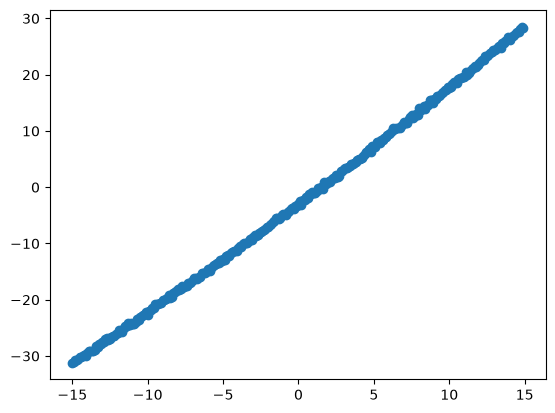

In [40]:
plt.scatter(x[:, 0], y)

Доп.задание. Изобразите поверхность на 3d-графике

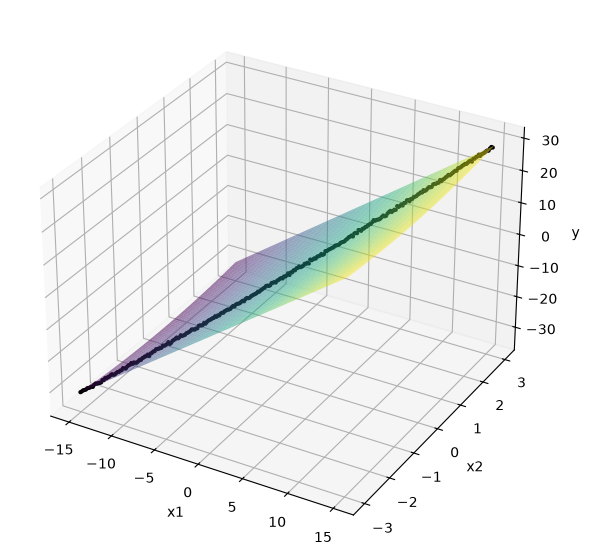

In [41]:
# точки датасета и «истинная» поверхность y = 2*x1 + 0.2*x2^2 - 3 без шума
g1, g2 = torch.meshgrid(torch.linspace(-15, 15, 60), torch.linspace(-3, 3, 60), indexing="ij")

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(g1, g2, 2 * g1 + 0.2 * g2**2 - 3, cmap="viridis", alpha=0.5)
ax.scatter(x[:, 0], x[:, 1], y.squeeze(), color="k", s=4)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
plt.show()


Прежде всего необходимо указать, какие тензоры будут требовать градиенты, с помощью параметра requires_grad. Если requires_grad=False, то это просто массив с числами, посчитать dx/dy не выйдет (по умолчанию).

Если же requires_grad=True, то фреймворк будит учитывать этот тензор при построении графа вычислений производной.
Например, станет возможно посчитать d(sin(log(x**2) - 3x))/dx.


Итак, как PyTorch строит вычислительный граф и вычисляет градиенты? Вершинами графа являются объекты класса torch.autograd.Node, например, AddBackward, MulBackward - это результаты выполнения операций. Ребрами же являются сами тензоры. Соответственно, у каждого тензора,  для которого требуется вычисление градиентов, есть ссылка на функцию .grad_fn, которая градиент создала, и значение самих частных производных (тоже тензор) .grad. Если градиенты неприменимы, то эта функция станет None.



In [42]:
a = torch.rand(5,2, requires_grad=True)
b = torch.rand(2, 1, requires_grad=True)

In [43]:
mult_res = a @ b
res = mult_res.sum()
res

tensor(1.6196, grad_fn=<SumBackward0>)

In [44]:
mult_res

tensor([[0.3981],
        [0.3276],
        [0.4003],
        [0.2500],
        [0.2436]], grad_fn=<MmBackward0>)

In [45]:
mult_res.grad_fn.next_functions

((<AccumulateGrad at 0x10e4f7be0>, 0), (<AccumulateGrad at 0x10e4f7910>, 0))

In [46]:
print(a.grad)

None


А как же получить значения градиентов? Тензоры что-то содержат, операции все известны. На самом деле еще при вычислении значения выражения уже известно, какие операции производятся, поэтому и производную можно посчитать. То, как конкретно это делается, вы узнаете на лекции по backpropagation.

In [47]:
res.backward()

In [48]:
b.grad.data

tensor([[1.1716],
        [2.3948]])

In [49]:
mult_res.grad

/var/folders/gz/8kbvnrzd7mgchwyzblydqst00000gn/T/ipykernel_84177/6217836.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /Users/runner/work/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:493.)
  mult_res.grad


Граф перестраивается на каждом проходе. Это удобно - мы не зависим от размеров семпплов и батчей, но дает оверхед, который может стать значительным у больших моделей. 

Начиная с PyTorch 2.0 появилась возможность получать статические вычислительные графы, что позволяет сильно ускорить обучение, об этом детально мы, возможно, поговорим позже. Пока что просто помните, что если вам необходимо ускорить инференс или обучение модели, один из простейших вариантов - использовать torch.compile и статические графы. В таком случае, многие операции на ускорителе можно оптимизировать, а лишние этапы перестройки опустить.


Перейдем к нашим данным. Попробуем обучить простую линейную модель с помощью градиентного спуска.

In [50]:
w = torch.rand(1, 2, requires_grad=True)
b = torch.rand(1, requires_grad=True)
y_pred = w @ x.T + b  # [1, 2] @ [2, 300] -> [1, 300], как и y
loss = torch.mean((y_pred - y) ** 2)
loss.backward()

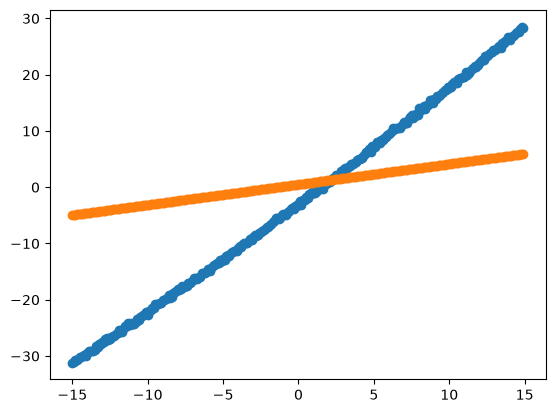

In [51]:
plt.scatter(x[:, 0], y)
plt.scatter(x[:, 0], y_pred.detach().numpy())

Пока не слишком похоже на то, что мы хотим. Для того, чтобы изменения применились, нужно сделать шаг градиентного спуска.

**Задание**. Проведите 100 итераций градиентного спуска для данного набора.
Для этого надо вспомнить, как выглядит этот алгоритм для линейной регрессии

In [52]:
w.grad

tensor([[-245.5416,  -49.1083]])

iter   0: loss=143.2171  w=[[1.50886070728302, 0.9707425832748413]]  b=0.063  grad_w=[[-202.5208282470703, -40.504154205322266]]
iter  10: loss=  5.3742  w=[[1.7942891120910645, 1.0278280973434448]]  b=-0.173  grad_w=[[0.002856914885342121, 0.0005699492176063359]]
iter  20: loss=  4.4533  w=[[1.794150948524475, 1.027800440788269]]  b=-0.386  grad_w=[[0.0026380668859928846, 0.0005288214306347072]]
iter  30: loss=  3.7000  w=[[1.7940260171890259, 1.0277754068374634]]  b=-0.578  grad_w=[[0.0023938757367432117, 0.0004788170917890966]]
iter  40: loss=  3.0839  w=[[1.7939128875732422, 1.0277527570724487]]  b=-0.752  grad_w=[[0.0021641438361257315, 0.0004336217825766653]]
iter  50: loss=  2.5800  w=[[1.7938107252120972, 1.027732253074646]]  b=-0.910  grad_w=[[0.001964083407074213, 0.000392063579056412]]
iter  60: loss=  2.1679  w=[[1.7937182188034058, 1.0277137756347656]]  b=-1.052  grad_w=[[0.0017698444426059723, 0.00035387679236009717]]
iter  70: loss=  1.8308  w=[[1.7936345338821411, 1.027

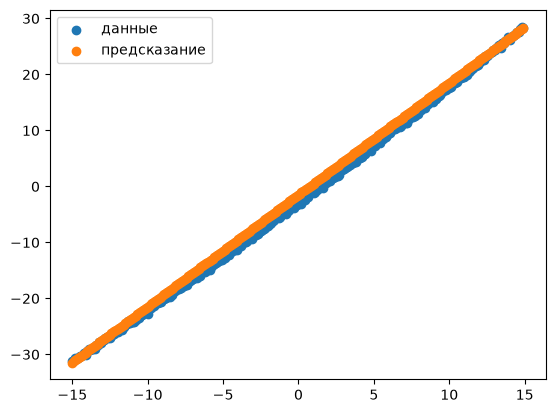

In [53]:
torch.manual_seed(0)
w = torch.rand(1, 2, requires_grad=True)
b = torch.rand(1, requires_grad=True)
# при lr = 0.1 спуск расходится: x1 доходит до 15, и градиент по w1 огромный
lr = 0.005

for i in range(100):

    y_pred = w @ x.T + b
    loss = torch.mean((y_pred - y) ** 2)
    loss.backward()
    with torch.no_grad():
        # torch.no_grad() выключает обернутую часть из графа
        # Почему мы не можем сделать так?
        #  w  = w  - 0.1 * w.grad
        # Ответ: это создаст НОВЫЙ тензор (внутри no_grad ещё и без requires_grad), а не изменит лист графа.
        # На следующей итерации w.grad будет None, и обучение сломается. Поэтому обновляем на месте:
        w -= lr * w.grad
        b -= lr * b.grad
    if i % 10 == 0 or i == 99:
        print(f"iter {i:3d}: loss={loss.item():8.4f}  w={w.data.tolist()}  b={b.item():.3f}  grad_w={w.grad.tolist()}")

    # На каждой итерации нужно занулить градиенты
    # - иначе они будут копиться и приведут к непредвиденным результатам
    w.grad.data.zero_()
    b.grad.data.zero_()

plt.scatter(x[:, 0], y, label="данные")
plt.scatter(x[:, 0], y_pred.detach().numpy(), label="предсказание")
plt.legend()

# Пайплайн обучения

Кроме собственно тензоров, функций потерь и градиентов, основные составляющие библиотеки как и всегда - датасеты и модели. При этом торч позволяет довольно свободно составлять и то, и другое из простейших блоков, лишь поддерживая необходимые интерфейсы.

Импортируем torch.nn - тут находятся классы, реализующие слои, лоссы, функции ошибок и тд. 
Для примера я использую стандартный датасет для компьютерного зрения - MNIST - содержащий цифры от 0 до 9 в разном написании. Поэтому импортируются некоторые подмодули torchvision


In [54]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [55]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Pytorch позволяет использовать открытые датасеты с хаба. Они все являются подклассами `torch.utils.data.Dataset` и имплементируют методы, специфичные для этого класса данных. Обычно они используются для прототипирования и бенчмаркинга и могут быть загружены по необходимости. Однако если для задачи необxодимо что-то кроме предполагаемой разработчиками функциональности, нужно либо отнаследовать один из них, либо напрямую `torch.utils.data.Dataset`.

Давайте загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist) - один из таких простых бенчмарк-датасетов для компьютерного зрения. Каждый семпл - это черно-белое изображение размером 28х28 с каким-то предметом одежды и ассоциированным классом. Всего набор содержит 60000 + 10000 изображений и 10 классов.


In [56]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  8%|▊         | 2.06M/26.4M [00:00<00:01, 19.9MB/s]

 15%|█▌        | 4.06M/26.4M [00:00<00:01, 15.9MB/s]

 22%|██▏       | 5.70M/26.4M [00:00<00:01, 15.2MB/s]

 28%|██▊       | 7.37M/26.4M [00:00<00:01, 15.4MB/s]

...

 39%|███▊      | 1.70M/4.42M [00:00<00:00, 15.7MB/s]

 78%|███████▊  | 3.44M/4.42M [00:00<00:00, 16.6MB/s]

100%|██████████| 4.42M/4.42M [00:00<00:00, 12.4MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 7.33MB/s]

In [57]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [58]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

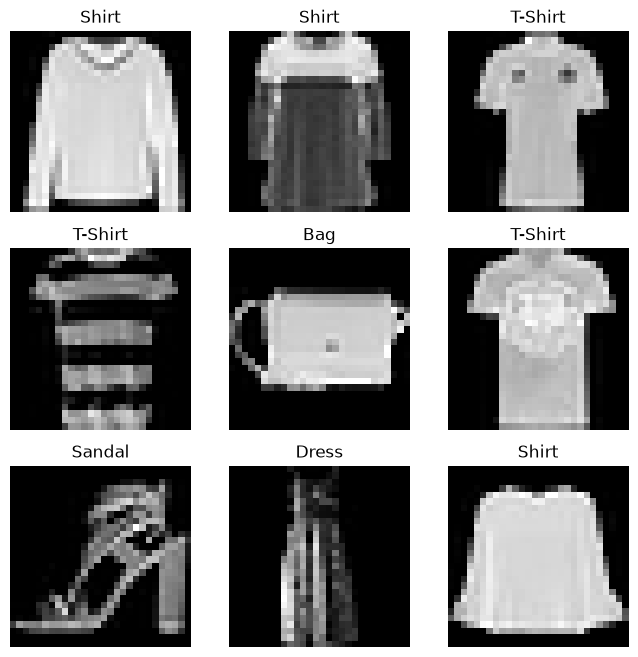

In [59]:
plot_samples(train_data, labels_map, cols=3, rows=3)

Каждый датасет в Pytorch должен наследоваться от класса Dataset и обязательно имплементировать методы `__init__, __len__, __getitem__`. В `__init__` обычно кроме прочего определяются трансформации, которые будут применяться к данным. Это может быть преобразование PIL.Image в тензоры, добавление шума, сдвиги и т.д. 
Pytorch предоставляет большое количество трансформаций, но наиболее популярная и удобная библиотека, реализующая трансформации для изображений - *albumentations*. 

`__len__` - должна возвращать размер датасета (например, чисо строк в файле с аннотациями)

`__getitem__` - должен возвращать семпл данных, например, вектор признаков и y. Однако он может возвращать еще и дополнительную информацию, например, y может состоять из набора bboxoв и  сегментационных масок для детекции, класса изображения итп. Обычно возвращается tuple. В целом, возвращаться может любая структура, которую можно представить как набор тензоров, соответствующих одному семплу и входу модели.
Внутри этого метода может происходить загрузка семпла, его трансформации и другие необходимые манипуляции. Очевидно, что он может возвращать не только изображение, но и любые другие данные, и временные ряды, и табличные данные, и облака точек, и другое. 


Давайте реализуем такой датасет для FashionMNIST. Конечно, можно было бы спокойно использовать встроенный, но так не интересно )

In [60]:
from torchvision.datasets.mnist import read_image_file, read_label_file

In [61]:
class FashionMNISTDataset(Dataset):
    def __init__(self, file_dir, train=True, transform=None, target_transform=None):
        self.transform = transform
        self.target_transform = target_transform
        self.train = train
        image_file = f"{'train' if self.train else 't10k'}-images-idx3-ubyte"
        self.data = read_image_file(os.path.join(file_dir, image_file))

        label_file = f"{'train' if self.train else 't10k'}-labels-idx1-ubyte"
        self.targets = read_label_file(os.path.join(file_dir, label_file))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx]
        label = self.targets[idx]
        
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

Проинициализируйте ваш новый датасет так же, как и ранее встроенный.

In [62]:
# FashionMNISTDataset читает исходные файлы, которые скачал встроенный датасет выше
RAW_DIR = "data/FashionMNIST/raw"


def to_float(img):
    # uint8 [28, 28] -> float [1, 28, 28] в [0, 1], как делает ToTensor
    return img.float().div(255).unsqueeze(0)


train_data = FashionMNISTDataset(RAW_DIR, train=True, transform=to_float)
test_data = FashionMNISTDataset(RAW_DIR, train=False, transform=to_float)

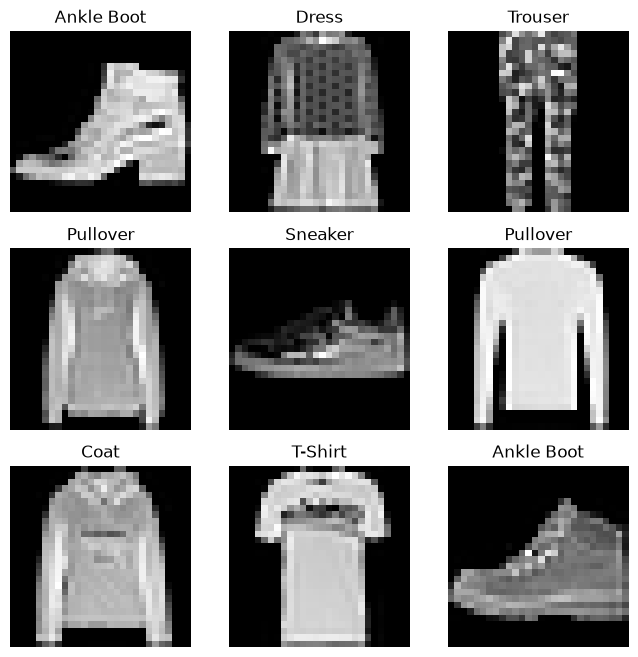

In [63]:
plot_samples(train_data, labels_map, cols=3, rows=3)

Датасет возвращает один семпл за раз, однако часто наши мощности позволяют обрабатывать больше данных. При работе с таблицами модель получает на вход вообще весь набор сразу или достаточно большими порциями. Когда речь заходит о тензорах и наборах с сотнями тысяч и даже миллионами семплов, это невозможно. На помощь приходит батчевая обработка, когда из датасета берутся небольшие порции данных за раз (используя индекс). За соединение семплов во вход модели отвечает класс DataLoader. Каждую эпоху данные шаффлятся, чтобы уменьшить переобучение. 

In [64]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


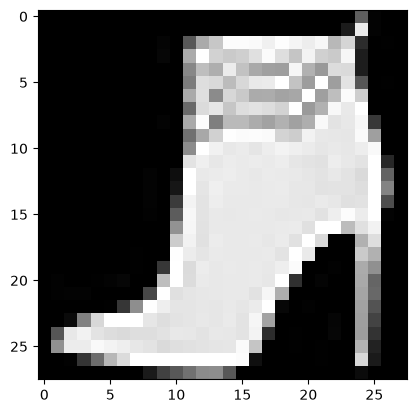

Label: 9


In [65]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

Глубокое обучение чаще всего связывают с GPU, и не зря. Имея дело с тензорами и тензорными вычислениями, мы производим огромное количество элементарных операций. Каждое ядро CPU способно произвести только одно вычисление за такт. GPU был создан для обработки графики, где требуется также большое количество простых вычислений, и поэтому может ускорить обработку данных в тысячи раз. Это все должно быть хорошо Вам известно из других курсов)

К сожалению, часто компьютер не поддерживает вычисления на GPU, например, у него просто нет дискретной видеокарты. Pytorch позволяет проводить все операции на CPU, так что его можно использовать где угодно.



In [66]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cpu device


*Дополнительное задание: адаптируйте весь код для `accelerate`. Это очень удобная библиотека для адаптации PyTorch кода для любой распределенной конфигурации. Кроме того, она позволяет упростить работу, даже если нам нужно перенести вычисления на GPU или CPU, автоматизируя этот процесс (иначе нам нужно постоянно вызывать `.to(device)`)*
*Для этого импортируйте нужный Accelerator из accelerate. Далее достаточно вызвать accelerator.prepare(elements)*

Теперь создадим класс модели и интстанциируем её. В данном случае это простой перцептрон с тремя слоями. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.
Каждая модель должна имплементировать два метода - `__init__` и `forward(self, *args, **kwargs)`. В первом обычно задается ее структура и другие параметры. Модель  может даже содержать другие модели!

`forward` получает на вход Х, но он может получать несколько разных входов, маски и тд. Обычно возвращаются либо выходы с последнего слоя (один или несколько). Но, например, стандартные модели детекции возвращают в режиме обучения значение лосса, а непосредственные предсказания только в режиме тестирования.

Вызывая `model(data)`, на самом деле мы вызываем именно метод `forward`

Для того, чтобы понять, как устроен слой в Pytorch, создадим простой слой для превращения изображения в вектор.
Пусть это будет класс MyFlatten. Изображения (и, что более актуально, промежуточные представления или, иными словами, карты, внутри модели) изначально имеют размер N x C x H x W, где:

N - число семплов в батче
C - число каналов на входе в конкретный слой. Если вход с 3 каналами, это 3, но в середине модели это может быть любое число, например, 128.
H - высота карты
W - ширина карты

Когда мы делаем что-то вроде двумерной свертки, это стандартное представление данных, которое позволяет восстановить пространственные зависимости между элементами карты. Однако, когда мы используем полносвязные модели, каждый семпл представлен единым вектором. В простом случае больше не нужно разделять разные каналы, строки и столбцы данных. Таким образом, мы используем операцию "вытянуть в вектор", чтобы превратить значения C x H x W в представление C * H * W. 

**Задание**: допишите класс MyFlatten. Этот слой при вызове должен принимать на вход тензор размера B x C x H x W и возвращать тензор размера B x [C * H * W]. Пример: батч картинок 2 x 3(rgb) x 16(h) x 16(w)] -> 2 x 768

In [67]:
class MyFlatten(nn.Module):
    def forward(self, x):
        # B x C x H x W -> B x (C * H * W); reshape, а не view: вход может быть не непрерывным в памяти
        return x.reshape(x.size(0), -1)


MyFlatten()(torch.randn(2, 3, 16, 16)).shape

torch.Size([2, 768])

In [68]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = MyFlatten()
        self.fc = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.fc(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): MyFlatten()
  (fc): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


Слои: http://pytorch.org/docs/nn.html

Активации: http://pytorch.org/docs/nn.html#non-linear-activations

Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [69]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Задание: 
1) Выберите как минимум еще 2 разные функции ошибки из https://pytorch.org/docs/stable/nn.html#loss-functions и обучите модель с ними
2) Выберите как минимум еще 1 оптимизатор из https://pytorch.org/docs/stable/optim.html и обучите каждую из моделей с ним

В результате у вас должна получиться таблица с лучшими значениями лосса для каждого случая для обучения и теста. В идеале оформите их в виде pandas.DataFrame или другой таблицы с удобным выводом.

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [70]:
def train(dataloader, model, loss_fn, optimizer, verbose=True):
    """Одна эпоха обучения. Возвращает средний loss по эпохе (для трекинга лучшего значения)."""
    size = len(dataloader.dataset)
    model.train()
    total_loss = 0
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        # Compute prediction error
        preds = model(inputs)
        loss = loss_fn(preds, targets)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        if verbose and batch_idx % 300 == 0:
            loss, current = loss.item(), (batch_idx + 1) * len(inputs)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    return total_loss / len(dataloader)

In [71]:
def test(dataloader, model, loss_fn, num_classes=10, verbose=True):
    """Возвращает loss, accuracy и macro-усреднённые precision/recall на dataloader."""
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0, 0
    # confusion[i, j] — сколько объектов класса i предсказано как j
    confusion = torch.zeros(num_classes, num_classes, dtype=torch.long)
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            preds = model(inputs)
            test_loss += loss_fn(preds, targets).item()
            pred_labels = preds.argmax(1)
            num_correct += (pred_labels == targets).type(torch.float).sum().item()
            pairs = targets.cpu() * num_classes + pred_labels.cpu()
            confusion += torch.bincount(pairs, minlength=num_classes**2).view(num_classes, num_classes)
    test_loss /= num_batches
    accuracy = num_correct / size
    tp = confusion.diag().float()
    precision = (tp / confusion.sum(0).clamp(min=1)).mean().item()  # среди предсказанных как класс c
    recall = (tp / confusion.sum(1).clamp(min=1)).mean().item()  # среди настоящих объектов класса c
    if verbose:
        print(
            f"Test: accuracy {100 * accuracy:>0.1f}%, precision {100 * precision:>0.1f}%, "
            f"recall {100 * recall:>0.1f}%, avg loss {test_loss:>8f}"
        )
    return {"loss": test_loss, "accuracy": accuracy, "precision": precision, "recall": recall}

Задание: Добавьте метрики precision и recall для проверки

In [72]:
torch.manual_seed(0)
model = NeuralNetwork().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

epochs = 10
best = {"train loss": float("inf"), "test loss": float("inf")}
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loss = train(train_dataloader, model, loss_fn, optimizer)
    metrics = test(test_dataloader, model, loss_fn)
    best["train loss"] = min(best["train loss"], train_loss)
    best["test loss"] = min(best["test loss"], metrics["loss"])
best

Epoch 1
-------------------------------
loss: 2.300577  [   64/60000]


loss: 2.265884  [19264/60000]
loss: 2.205814  [38464/60000]


loss: 2.162513  [57664/60000]
Test: accuracy 50.3%, precision 50.4%, recall 50.3%, avg loss 2.162532
Epoch 2
-------------------------------
loss: 2.173477  [   64/60000]


loss: 2.095542  [19264/60000]


loss: 2.021259  [38464/60000]
loss: 1.909221  [57664/60000]


...

loss: 0.677479  [38464/60000]
loss: 0.738915  [57664/60000]


Test: accuracy 69.8%, precision 70.3%, recall 69.7%, avg loss 0.810298
Epoch 10
-------------------------------
loss: 0.820719  [   64/60000]
loss: 0.726505  [19264/60000]


loss: 0.653830  [38464/60000]
loss: 0.897623  [57664/60000]


Test: accuracy 71.5%, precision 71.7%, recall 71.5%, avg loss 0.779158


{'train loss': 0.7781921814499634, 'test loss': 0.7791575026360287}

Осталось сохранить модель для дальнейшего использования. 

In [73]:
torch.save(model.state_dict(), "best_model.pth")

Какая точность получилась? 

In [74]:
print(f"Точность на тесте: {metrics['accuracy']:.1%}")

Точность на тесте: 71.5%


**Ответ:** около 71.5 % на тесте после 10 эпох. Это немного: SGD с `lr=1e-3` очень медленный, loss к концу ещё
заметно падает (0.78), то есть модель недообучена. Та же сеть с Adam набирает ≈86–87 % уже за 5 эпох (см. таблицу ниже).

### Задание: другие функции ошибки и оптимизаторы

Кроме `CrossEntropyLoss` берём:
- `MultiMarginLoss` — многоклассовый hinge loss, как в SVM;
- MSE между softmax-вероятностями и one-hot меткой (Brier score). Ему нужны другие входы, поэтому сделана небольшая обёртка.

Оптимизаторы: SGD и Adam. Для SGD взят `lr=1e-2`: с `1e-3` за 5 эпох почти ничего не успевает выучиться.
Абсолютные значения разных лоссов между собой несравнимы, поэтому в таблице есть и accuracy.

In [75]:
class MSEOnProbs(nn.Module):
    """MSE между softmax-вероятностями и one-hot меткой."""

    def forward(self, logits, targets):
        one_hot = nn.functional.one_hot(targets, logits.size(1)).float()
        return nn.functional.mse_loss(logits.softmax(1), one_hot)


LOSSES = {
    "CrossEntropyLoss": nn.CrossEntropyLoss,
    "MultiMarginLoss": nn.MultiMarginLoss,
    "MSE(softmax, one-hot)": MSEOnProbs,
}
OPTIMIZERS = {
    "SGD(lr=1e-2)": lambda params: torch.optim.SGD(params, lr=1e-2),
    "Adam(lr=1e-3)": lambda params: torch.optim.Adam(params, lr=1e-3),
}
EPOCHS = 5

rows = []
for loss_name, make_loss in LOSSES.items():
    for opt_name, make_opt in OPTIMIZERS.items():
        torch.manual_seed(0)
        model = NeuralNetwork().to(device)
        loss_fn, optimizer = make_loss(), make_opt(model.parameters())
        history = []
        for _ in range(EPOCHS):
            train_loss = train(train_dataloader, model, loss_fn, optimizer, verbose=False)
            history.append((train_loss, test(test_dataloader, model, loss_fn, verbose=False)))
        rows.append({
            "loss": loss_name,
            "optimizer": opt_name,
            "лучший train loss": min(h[0] for h in history),
            "лучший test loss": min(h[1]["loss"] for h in history),
            "лучшая test accuracy": max(h[1]["accuracy"] for h in history),
        })

pd.DataFrame(rows).round(4)

,loss,optimizer,лучший train loss,лучший test loss,лучшая test accuracy
0,CrossEntropyLoss,SGD(lr=1e-2),0.4826,0.4986,0.8220
1,CrossEntropyLoss,Adam(lr=1e-3),0.2795,0.3690,0.8643
2,MultiMarginLoss,SGD(lr=1e-2),0.0857,0.0864,0.7855
3,MultiMarginLoss,Adam(lr=1e-3),0.0358,0.0461,0.8685
4,"MSE(softmax, one-hot)",SGD(lr=1e-2),0.0872,0.0868,0.4859
5,"MSE(softmax, one-hot)",Adam(lr=1e-3),0.0158,0.0188,0.8683


**Выводы.**
- С Adam все три функции ошибки дают почти одинаковую точность, ≈86–87 %.
- С SGD разница большая: CrossEntropy 82 %, MultiMargin 79 %, а MSE на вероятностях почти не учится (49 %).
  Градиент MSE проходит через softmax и при уверенных неверных предсказаниях становится очень маленьким (насыщение).
  У кросс-энтропии этой проблемы нет: её градиент по логитам равен просто `p - one_hot`.
- Adam лучше SGD во всех трёх случаях: адаптивный шаг компенсирует неудачный масштаб градиентов.

Задание: Перепишите датасет FashionMNISTDataset так, чтобы он возвращал вектор вместо матрицы и мою модель без слоя MyFlatten(). Запустите обучение заново. Какая точность получилась теперь?

In [76]:
class FashionMNISTVectorDataset(FashionMNISTDataset):
    """Тот же датасет, но картинка сразу вытянута в вектор из 784 чисел."""

    def __getitem__(self, idx):
        image, label = super().__getitem__(idx)
        return image.reshape(-1), label


class NeuralNetworkNoFlatten(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.fc(x)


train_vec = FashionMNISTVectorDataset(RAW_DIR, train=True, transform=to_float)
test_vec = FashionMNISTVectorDataset(RAW_DIR, train=False, transform=to_float)
train_vec_loader = DataLoader(train_vec, batch_size=64, shuffle=True)
test_vec_loader = DataLoader(test_vec, batch_size=64, shuffle=True)
print(train_vec[0][0].shape)

# те же сид, оптимизатор и число эпох, что и в исходном обучении выше
torch.manual_seed(0)
model = NeuralNetworkNoFlatten().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
for t in range(10):
    train(train_vec_loader, model, loss_fn, optimizer, verbose=False)
    vec_metrics = test(test_vec_loader, model, loss_fn, verbose=False)
    print(f"epoch {t + 1}: test accuracy {vec_metrics['accuracy']:.1%}")

torch.Size([784])


epoch 1: test accuracy 50.3%


epoch 2: test accuracy 59.4%


epoch 3: test accuracy 61.5%


epoch 4: test accuracy 63.2%


...

epoch 6: test accuracy 66.2%


epoch 7: test accuracy 67.2%


epoch 8: test accuracy 68.4%


epoch 9: test accuracy 69.8%


epoch 10: test accuracy 71.5%


**Ответ:** точность та же, 71.5 %, и совпадает по всем эпохам до десятой доли процента. Вытягивание в вектор не
имеет параметров, и неважно, где его делать, в датасете или в модели. При одинаковом сиде веса `Linear` и порядок
батчей совпадают, поэтому обучение идёт идентично.

Задание: придумайте свою собственную модель. Улучшите результат (но без сверток)

Своя модель (без свёрток): шире и глубже исходной, с `BatchNorm1d` и `Dropout` между слоями, оптимизатор AdamW
и косинусное расписание learning rate. Для подбора гиперпараметров (совет 4 ниже) отделяем 10 % train в валидацию,
а на тесте модель проверяем один раз в конце.

In [77]:
from torch.utils.data import random_split


class MyMLP(nn.Module):
    def __init__(self, hidden=(1024, 512, 256), dropout=0.3):
        super().__init__()
        layers, d = [], 28 * 28
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


torch.manual_seed(0)
train_part, val_part = random_split(train_vec, [54000, 6000])
train_loader = DataLoader(train_part, batch_size=128, shuffle=True)
val_loader = DataLoader(val_part, batch_size=512)

EPOCHS = 15
model = MyMLP().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
for t in range(EPOCHS):
    train_loss = train(train_loader, model, loss_fn, optimizer, verbose=False)
    scheduler.step()
    val = test(val_loader, model, loss_fn, verbose=False)
    print(f"epoch {t + 1:2d}: train loss {train_loss:.4f}, val loss {val['loss']:.4f}, val accuracy {val['accuracy']:.1%}")

print()
my_metrics = test(test_vec_loader, model, loss_fn)

epoch  1: train loss 0.4955, val loss 0.3745, val accuracy 86.1%


epoch  2: train loss 0.3779, val loss 0.3463, val accuracy 87.1%


epoch  3: train loss 0.3451, val loss 0.3264, val accuracy 87.8%


epoch  4: train loss 0.3156, val loss 0.3131, val accuracy 88.3%


epoch  5: train loss 0.2971, val loss 0.3152, val accuracy 88.1%


...

epoch 11: train loss 0.1979, val loss 0.2698, val accuracy 90.1%


epoch 12: train loss 0.1837, val loss 0.2712, val accuracy 90.4%


epoch 13: train loss 0.1734, val loss 0.2630, val accuracy 90.6%


epoch 14: train loss 0.1647, val loss 0.2642, val accuracy 90.6%


epoch 15: train loss 0.1596, val loss 0.2648, val accuracy 90.6%

Test: accuracy 90.4%, precision 90.4%, recall 90.4%, avg loss 0.287089


**Итог:** 90.4 % на тесте (precision и recall тоже 90.4 %) против 71.5 % у исходной модели с SGD и ≈86.4 % у неё же с Adam.
Помогли AdamW вместо SGD, BatchNorm (быстрее и стабильнее сходится), Dropout (train loss 0.16 при val loss 0.26, без него
переобучение было бы сильнее) и косинусное уменьшение learning rate: последние эпохи дают ещё +0.5–1 %.

При подборе гиперпараметров (это те параметры, которые не обучаются, например, lr) и обучении модели помните:
1. Если параметры выбраны хорошо, улучшение видно уже после нескольких сотен итераций.
2. Настраивайте гиперпараметры от грубых значений к точным: начните с тестирования большого диапазона гиперпараметров всего за несколько итераций обучения, чтобы найти комбинации параметров, которые вообще работают.
3. После того, как вы нашли несколько наборов параметров, которые, по-видимому, работают, выполните более тщательный поиск по этим параметрам. Возможно, вам придется тренировать модель большее число эпох.
4. Нужно использовать валидационный набор для поиска. Этот набор нужно выделить из тренировочного и вызывать на нем функцию test.

Задание: Перепишите датасет FashionMNISTDataset так, чтобы он возвращал вектор вместо матрицы

In [78]:
# сделано выше: FashionMNISTVectorDataset